Best Task Allocation:
Processor 1:  [2, 4, 8]
Processor 2:  [1, 3, 5, 9]
Processor 3:  [6, 7, 10]
Processor Workloads: [19. 19. 17.]
Minimum Makespan: 19.0


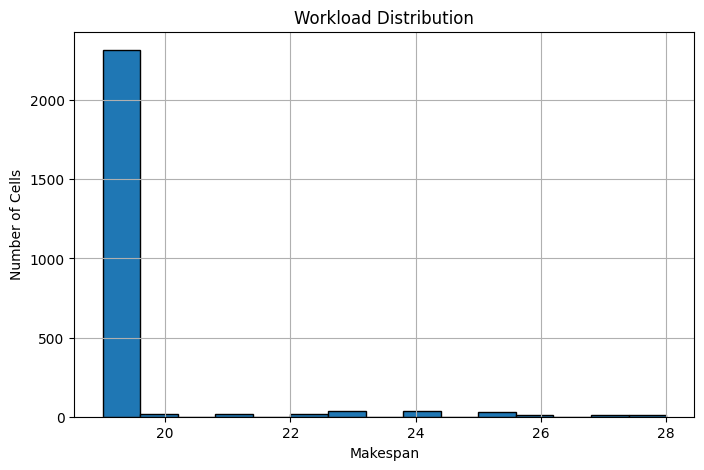

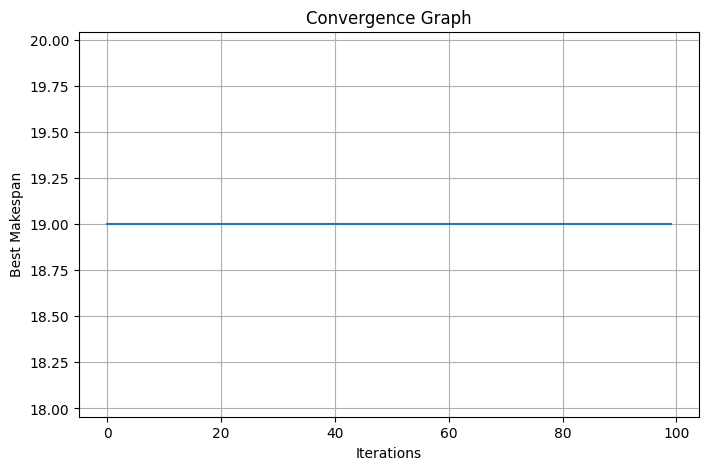

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

tasks = [8, 6, 5, 7, 4, 9, 3, 6, 2, 5]
processors = 3
grid_size = 5
iterations = 100

grid = np.random.randint(0, processors, (grid_size, grid_size, len(tasks)))
convergence = []
workload = []

def fitness(solution):
    loads = np.zeros(processors)
    for i, p in enumerate(solution):
        loads[p] += tasks[i]
    return max(loads)

def neighbors(i, j):
    return [
        ((i - 1) % grid_size, j),
        ((i + 1) % grid_size, j),
        (i, (j - 1) % grid_size),
        (i, (j + 1) % grid_size)
    ]

for _ in range(iterations):
    new_grid = grid.copy()

    for i in range(grid_size):
        for j in range(grid_size):
            best = grid[i, j].copy()

            for ni, nj in neighbors(i, j):
                candidate = grid[ni, nj]

                if fitness(candidate) < fitness(best):
                    best = candidate.copy()

            if np.random.rand() < 0.1:
                k = np.random.randint(len(tasks))
                best[k] = np.random.randint(processors)

            new_grid[i, j] = best

    grid = new_grid

    scores = [fitness(grid[i, j]) for i in range(grid_size) for j in range(grid_size)]
    convergence.append(min(scores))
    workload.extend(scores)

best = grid[np.unravel_index(np.argmin([fitness(s) for s in grid.reshape(-1, len(tasks))]), grid.shape[:2])]

loads = np.zeros(processors)

for i, p in enumerate(best):
    loads[p] += tasks[i]

print("Best Task Allocation:")
for p in range(processors):
    print(f"Processor {p+1}: ", [i+1 for i in range(len(tasks)) if best[i] == p])

print("Processor Workloads:", loads)
print("Minimum Makespan:", max(loads))

plt.figure(figsize=(8, 5))
plt.hist(workload, bins=15, edgecolor='black')
plt.xlabel("Makespan")
plt.ylabel("Number of Cells")
plt.title("Workload Distribution")
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(convergence)
plt.xlabel("Iterations")
plt.ylabel("Best Makespan")
plt.title("Convergence Graph")
plt.grid()
plt.show()